3. سوالات تکلیف

3-1-3 پایش تغییرات وزن و گرادیان در حین آموزش

3-1-3-1 شبکه CNN انتخاب شده خود را برای 20 دور آموزش دهید. ﺩﺭ ﭘﺎﻳﺎﻥ ﻫﺮ ﺩﻭﺭ، ﻣﻴﺎﻧﮕﻴﻦ ﻭ ﺍﻧﺤﺮﺍﻑ ﻣﻌﻴﺎﺭ ﻭﺯﻥ ﻫﺎﻱ ﻻﻳﻪ ﺍﻭﻝ ﻛﺎﻧﻮﻟﻮﺷﻦ ﺭﺍ ﻣﺤﺎﺳﺒﻪ ﻛﺮﺩﻩ ﻭ ﻧﻤﻮﺩﺍﺭ ﺗﻐﻴﻴﺮﺍﺕ ﺁﻧﻬﺎ ﺭﺍ ﺑﺮ ﺣﺴﺐ ﺩﻭﺭ ﺭﺳﻢ ﻛﻨﻴﺪ.

الف) ﺁﻳﺎ ﻭﺯﻥ ﻫﺎ ﺩﺭ ﻃﻮﻝ ﺯﻣﺎﻥ ﺑﻪ ﺳﻤﺖ ﻣﻘﺎﺩﻳﺮ ﺑﺰﺭﮔﺘﺮ ﻳﺎ ﻛﻮﭼﻜﺘﺮ ﺣﺮﻛﺖ ﻣﻲ ﻛﻨﻨﺪ؟ ﺁﻳﺎ ﭘﺪﻳﺪﻩ vanishing/exploding gradient مشاهده میشود؟

ب) ﺩﺭ ﺍﻭﺍﻳﻞ ﺁﻣﻮﺯﺵ ﻭ ﺍﻭﺍﺧﺮ ﺁﻣﻮﺯﺵ، ﺗﻮﺯﻳﻊ ﻭﺯﻥ ﻫﺎ ﺭﺍ ﺑﻪ ﺻﻮﺭﺕ ﻫﻴﺴﺘﻮﮔﺮﺍﻡ ﺭﺳﻢ ﻛﻨﻴﺪ ﻭ ﺗﻐﻴﻴﺮﺍﺕ ﺭﺍ ﺗﻮﺿﻴﺢ ﺩﻫﻴﺪ.

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datetime import datetime
import os
from pathlib import Path
import sys
import time

sys.path.append(str(Path.cwd().parent / 'src'))

from data_utils import get_moons_data, get_mnist_data
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)
np.random.seed(42)

In [2]:
X_train, X_test, y_train, y_test, train_loader, test_loader = get_mnist_data(batch_size=64)

In [3]:
class MNIST_CNN(nn.Module):
    def __init__(self, kernel_size1=5):
        super(MNIST_CNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=kernel_size1, stride=1, padding='same')
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)
        
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding='same')
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)
        
        self.fc = nn.Linear(32 * 7 * 7, 10)
    
    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


In [4]:
def train_and_monitor(model, train_loader, test_loader, epochs=20, lr=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    model.to(device)
    
    # Storage for metrics
    weight_means = []
    weight_stds = []
    grad_means = []
    grad_stds = []
    train_accs = []
    test_accs = []
    
    # Also store weight values for histograms (first and last epoch)
    initial_weights = None
    final_weights = None
    
    for epoch in range(epochs):
        # Training phase
        model.train()
        correct_train = 0
        total_train = 0
        
        # Record weights before backward pass (after previous epoch's update)
        # For epoch 0, record initial weights
        if epoch == 0:
            with torch.no_grad():
                w = model.conv1.weight.data.cpu().numpy()
                initial_weights = w.flatten().copy()
        
        # We'll accumulate gradients across batches to compute statistics at end of epoch
        all_grads = []
        
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            # Collect gradients of conv1 weights
            if model.conv1.weight.grad is not None:
                grads = model.conv1.weight.grad.data.cpu().numpy()
                all_grads.append(grads.flatten())
            
            # Accuracy stats
            _, predicted = torch.max(outputs, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()
        
        # After epoch, compute weight statistics
        with torch.no_grad():
            w = model.conv1.weight.data.cpu().numpy()
            weight_means.append(np.mean(w))
            weight_stds.append(np.std(w))
        
        # Compute gradient statistics for this epoch (over all batches)
        if all_grads:
            all_grads = np.concatenate(all_grads)
            grad_means.append(np.mean(all_grads))
            grad_stds.append(np.std(all_grads))
        else:
            grad_means.append(0)
            grad_stds.append(0)
        
        # Evaluation on test set
        model.eval()
        correct_test = 0
        total_test = 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total_test += labels.size(0)
                correct_test += (predicted == labels).sum().item()
        
        train_acc = 100 * correct_train / total_train
        test_acc = 100 * correct_test / total_test
        train_accs.append(train_acc)
        test_accs.append(test_acc)
        
        print(f"Epoch {epoch+1:2d}/{epochs} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}% | "
              f"Weight mean: {weight_means[-1]:.4f} | Weight std: {weight_stds[-1]:.4f} | "
              f"Grad mean: {grad_means[-1]:.6f} | Grad std: {grad_stds[-1]:.6f}")
    
    # Final weights for histogram
    with torch.no_grad():
        w = model.conv1.weight.data.cpu().numpy()
        final_weights = w.flatten().copy()
    
    return {
        'weight_means': weight_means,
        'weight_stds': weight_stds,
        'grad_means': grad_means,
        'grad_stds': grad_stds,
        'train_accs': train_accs,
        'test_accs': test_accs,
        'initial_weights': initial_weights,
        'final_weights': final_weights
    }


In [5]:
print("\n===== Training CNN with kernel_size=5 for 20 epochs =====")
model = MNIST_CNN(kernel_size1=5)
history = train_and_monitor(model, train_loader, test_loader, epochs=20, lr=0.001)



===== Training CNN with kernel_size=5 for 20 epochs =====
Epoch  1/20 | Train Acc: 95.03% | Test Acc: 98.01% | Weight mean: -0.0014 | Weight std: 0.1592 | Grad mean: -0.000582 | Grad std: 0.013010
Epoch  2/20 | Train Acc: 98.35% | Test Acc: 98.70% | Weight mean: -0.0028 | Weight std: 0.1695 | Grad mean: -0.000023 | Grad std: 0.010987
Epoch  3/20 | Train Acc: 98.73% | Test Acc: 98.96% | Weight mean: -0.0046 | Weight std: 0.1758 | Grad mean: 0.000001 | Grad std: 0.010382
Epoch  4/20 | Train Acc: 99.03% | Test Acc: 99.06% | Weight mean: -0.0061 | Weight std: 0.1813 | Grad mean: 0.000005 | Grad std: 0.009994
Epoch  5/20 | Train Acc: 99.20% | Test Acc: 99.08% | Weight mean: -0.0063 | Weight std: 0.1869 | Grad mean: -0.000012 | Grad std: 0.009993
Epoch  6/20 | Train Acc: 99.31% | Test Acc: 98.99% | Weight mean: -0.0114 | Weight std: 0.1922 | Grad mean: 0.000034 | Grad std: 0.009745
Epoch  7/20 | Train Acc: 99.40% | Test Acc: 98.87% | Weight mean: -0.0104 | Weight std: 0.1969 | Grad mean: -0

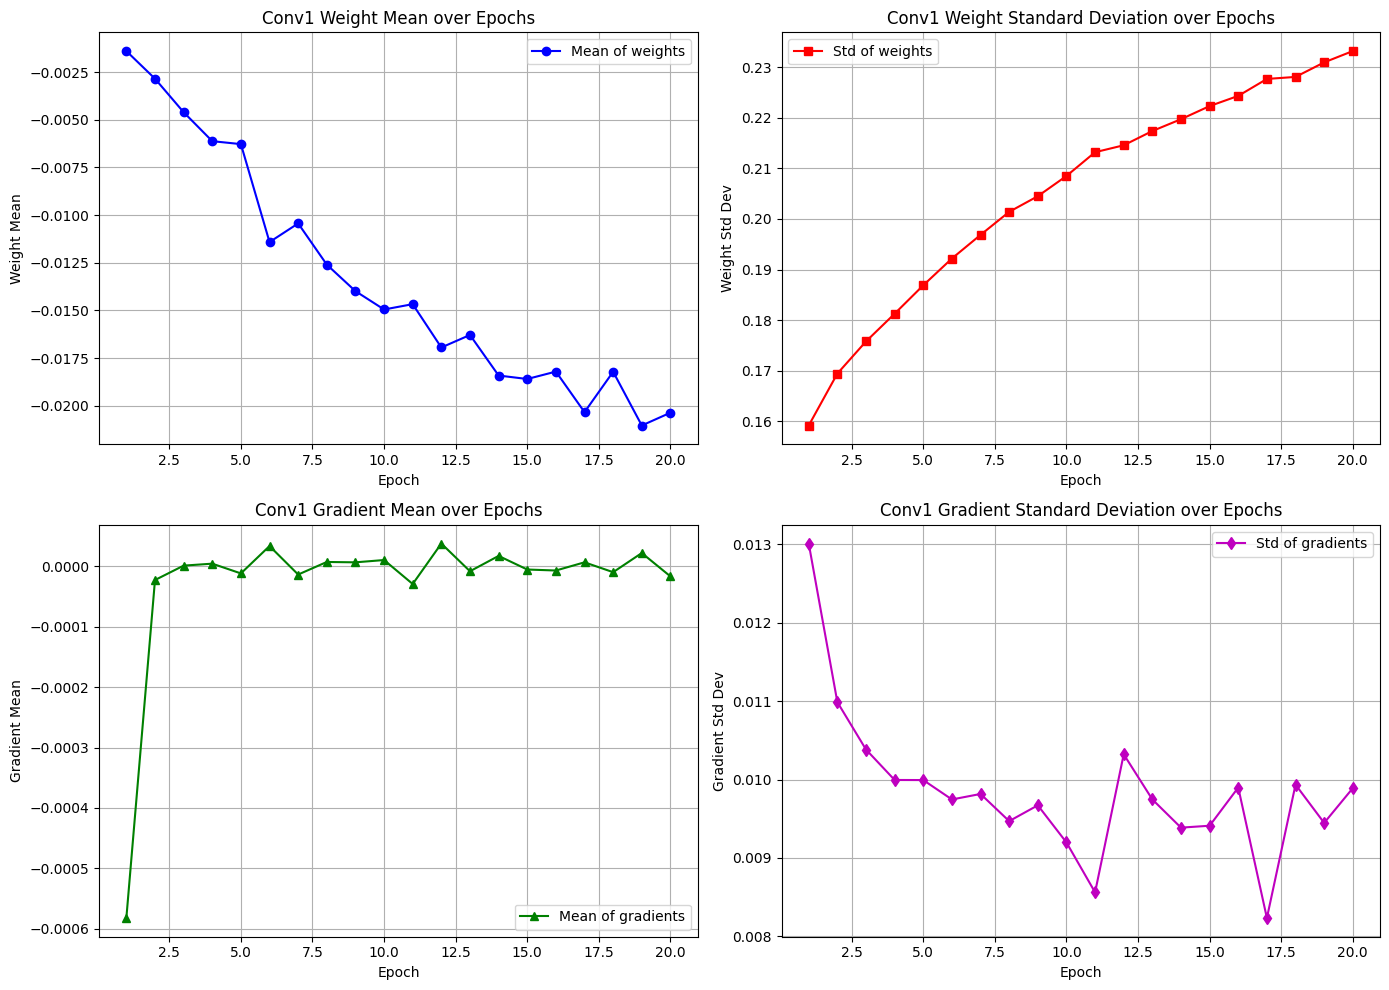

In [6]:
epochs = range(1, 21)

plt.figure(figsize=(14, 10))

# Plot weight mean and std
plt.subplot(2, 2, 1)
plt.plot(epochs, history['weight_means'], 'b-o', label='Mean of weights')
plt.xlabel('Epoch')
plt.ylabel('Weight Mean')
plt.title('Conv1 Weight Mean over Epochs')
plt.grid(True)
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(epochs, history['weight_stds'], 'r-s', label='Std of weights')
plt.xlabel('Epoch')
plt.ylabel('Weight Std Dev')
plt.title('Conv1 Weight Standard Deviation over Epochs')
plt.grid(True)
plt.legend()

# Plot gradient mean and std
plt.subplot(2, 2, 3)
plt.plot(epochs, history['grad_means'], 'g-^', label='Mean of gradients')
plt.xlabel('Epoch')
plt.ylabel('Gradient Mean')
plt.title('Conv1 Gradient Mean over Epochs')
plt.grid(True)
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(epochs, history['grad_stds'], 'm-d', label='Std of gradients')
plt.xlabel('Epoch')
plt.ylabel('Gradient Std Dev')
plt.title('Conv1 Gradient Standard Deviation over Epochs')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig('weight_gradient_stats_over_epochs.png', dpi=150)
plt.show()


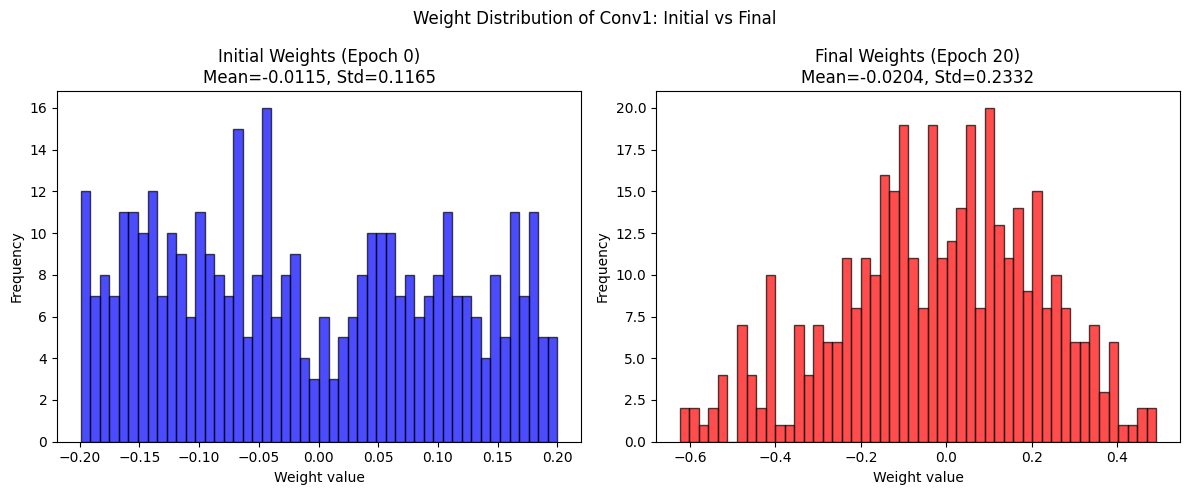

In [7]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(history['initial_weights'], bins=50, alpha=0.7, color='blue', edgecolor='black')
plt.title(f'Initial Weights (Epoch 0)\nMean={np.mean(history["initial_weights"]):.4f}, Std={np.std(history["initial_weights"]):.4f}')
plt.xlabel('Weight value')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.hist(history['final_weights'], bins=50, alpha=0.7, color='red', edgecolor='black')
plt.title(f'Final Weights (Epoch 20)\nMean={np.mean(history["final_weights"]):.4f}, Std={np.std(history["final_weights"]):.4f}')
plt.xlabel('Weight value')
plt.ylabel('Frequency')

plt.suptitle('Weight Distribution of Conv1: Initial vs Final')
plt.tight_layout()
plt.savefig('weight_histograms_initial_final.png', dpi=150)
plt.show()


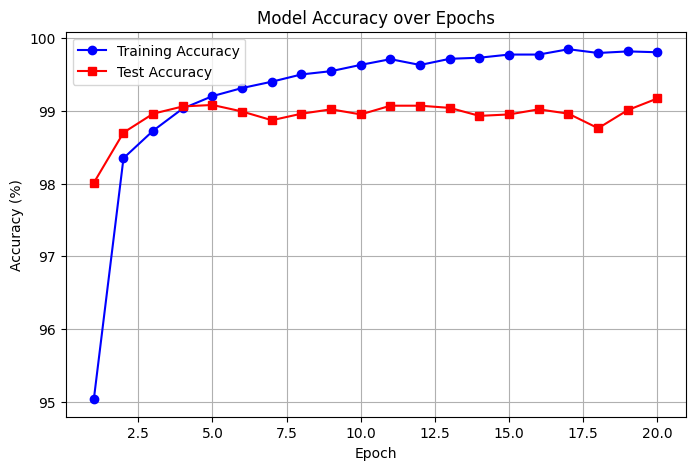

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(epochs, history['train_accs'], 'b-o', label='Training Accuracy')
plt.plot(epochs, history['test_accs'], 'r-s', label='Test Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Model Accuracy over Epochs')
plt.legend()
plt.grid(True)
plt.savefig('accuracy_curves_20epochs.png', dpi=150)
plt.show()


In [9]:
print("\n===== Summary of Weight/Gradient Behavior =====")
print(f"Initial weight mean: {np.mean(history['initial_weights']):.6f}, std: {np.std(history['initial_weights']):.6f}")
print(f"Final weight mean: {np.mean(history['final_weights']):.6f}, std: {np.std(history['final_weights']):.6f}")
print(f"Final test accuracy: {history['test_accs'][-1]:.2f}%")

# Check for vanishing/exploding gradients
max_grad_mean = max(history['grad_means'])
min_grad_mean = min(history['grad_means'])
print(f"\nGradient mean range: [{min_grad_mean:.6f}, {max_grad_mean:.6f}]")
if abs(max_grad_mean) > 10 or abs(min_grad_mean) > 10:
    print("Warning: Exploding gradient detected (gradient magnitude > 10).")
elif abs(max_grad_mean) < 1e-5:
    print("Warning: Vanishing gradient detected (gradient magnitude < 1e-5).")
else:
    print("Gradient magnitudes are within normal range. No vanishing/exploding gradient issue.")

# Save all metrics to CSV
df = pd.DataFrame({
    'Epoch': epochs,
    'Weight_Mean': history['weight_means'],
    'Weight_Std': history['weight_stds'],
    'Gradient_Mean': history['grad_means'],
    'Gradient_Std': history['grad_stds'],
    'Train_Acc': history['train_accs'],
    'Test_Acc': history['test_accs']
})
df.to_csv('training_metrics_20epochs.csv', index=False)
print("\nMetrics saved to 'training_metrics_20epochs.csv'")


===== Summary of Weight/Gradient Behavior =====
Initial weight mean: -0.011459, std: 0.116539
Final weight mean: -0.020369, std: 0.233171
Final test accuracy: 99.17%

Gradient mean range: [-0.000582, 0.000038]
Gradient magnitudes are within normal range. No vanishing/exploding gradient issue.

Metrics saved to 'training_metrics_20epochs.csv'



3-1-3-2 ﺁﺯﻣﺎﻳﺶ ﻣﺤﻮ ﻳﺎ ﺍﻧﻔﺠﺎﺭ ﮔﺮﺍﺩﻳﺎن: یک ﺷﺒﻜﻪ ی ﻋﻤﻴﻖ CNN (ﻣﺜﻼ  ۱۰ ﻻﻳﻪ ﻛﺎﻧﻮﻟﻮﺷﻦ ﺑﺎ ﭘﺪﻳﻨﮓ ﻳﻜﺴﺎﻥ ﻭ ﺑﺪﻭﻥ ﺍﺗﺼﺎﻻت ﺑﺎﻗﻴﻤﺎﻧﺪﻩ ﻭ ﺑﺪﻭﻥ Batch Normalization) ﺭﻭی MNIST ﻃﺮﺍحی ﻛﻨﻴﺪ. ﺍﺯ ﺗﺎﺑﻊ ﻓﻌﺎﻝ ﺳﺎﺯی Sigmoid ﺩﺭ ﻻﻳﻪ ﻫﺎ ﺍﺳﺘﻔﺎﺩﻩ ﻛﻨﻴﺪ.


الف) ﻧﺮﻡ ﮔﺮﺍﺩﻳﺎﻥ ﻻﻳﻪ ﻫﺎی ﺍﻭﻝ ﻭ ﺁﺧﺮ ﺭﺍ ﺩﺭ ﻃﻮﻝ ﺁﻣﻮﺯﺵ (ﻣﺜﻼ  ﻫﺮ  100 batch) محاسبه ﻭ ﻧﻤﻮﺩﺍﺭ ﺁﻥ ﺭﺍ ﺭﺳﻢ ﻛﻨﻴﺪ. ﺁﻳﺎ ﮔﺮﺍﺩﻳﺎﻥ ﻻﻳﻪ ﻫﺎی ﺍﻭﻝ ﺑﺴﻴﺎﺭ کوچک ﺗﺮ ﺍﺯ ﻻﻳﻪ ﻫﺎی ﺁﺧﺮ ﻣﻲ ﺷﻮﺩ؟ (ﻣﺤﻮ ﮔﺮﺍﺩﻳﺎﻥ)

ب) ﻫﻤﺎﻥ ﺁﺯﻣﺎﻳﺶ ﺭﺍ ﺑﺎ ﺗﺎﺑﻊ ﻓﻌﺎﻝ ﺳﺎﺯی ReLU ﺗﻜﺮﺍﺭ ﻛﻨﻴﺪ. ﺁﻳﺎ ﺗﻔﺎﻭتی ﻣﺸﺎﻫﺪﻩ ﻣﻲ ﺷﻮﺩ؟

پ) ﺣﺎﻝ ﺑﻪ ﺟﺎی  Sigmoid، ﻭﺯﻥ دهی ﺍﻭﻟﻴﻪ ﺭﺍ ﺑﺴﻴﺎﺭ ﺑﺰﺭﮒ (ﻣﺜﻼ ﺿﺮﻳﺐ ۱۰) ﺍﻧﺘﺨﺎﺏ ﻛﻨﻴﺪ. ﭼﻪ ﺍﺗﻔﺎﻗﻲ ﺑﺮﺍی نرم ﮔﺮﺍﺩﻳﺎﻥ ﻣﻲ ﺍﻓﺘﺪ؟ (انفجار گرادیان)

3-1-3-3 راهنمایی ابزارها: برای نمایش وزن ها، نقشه های ویژگی و گرادیان ها به صورت تعاملی میتوانید از TensorBoard استفاده کنید. همچنین رسم نمودار های تغییرات وزن و گرادیان با matplotlib نیز قابل قبول است.

In [3]:
X_train, X_test, y_train, y_test, train_loader, test_loader = get_mnist_data(batch_size=64)

In [4]:
class DeepCNN(nn.Module):
    def __init__(self, num_layers=10, in_channels=1, hidden_channels=32, num_classes=10,
                 activation='sigmoid', weight_scale=1.0):
        super(DeepCNN, self).__init__()
        layers = []
        # First conv layer
        layers.append(nn.Conv2d(in_channels, hidden_channels, kernel_size=3, stride=1, padding='same'))
        if activation == 'sigmoid':
            layers.append(nn.Sigmoid())
        else:
            layers.append(nn.ReLU())
        
        # Subsequent conv layers
        for _ in range(num_layers - 1):
            layers.append(nn.Conv2d(hidden_channels, hidden_channels, kernel_size=3, stride=1, padding='same'))
            if activation == 'sigmoid':
                layers.append(nn.Sigmoid())
            else:
                layers.append(nn.ReLU())
        
        self.features = nn.Sequential(*layers)
        # Global average pooling to reduce spatial size to 1x1
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(hidden_channels, num_classes)
        
        # Custom weight initialization with scaling
        self.apply(self._init_weights(weight_scale))
    
    def _init_weights(self, scale):
        def init_fn(m):
            if isinstance(m, nn.Conv2d) or isinstance(m, nn.Linear):
                torch.nn.init.normal_(m.weight, mean=0.0, std=scale)
                if m.bias is not None:
                    torch.nn.init.zeros_(m.bias)
        return init_fn
    
    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


In [5]:
def compute_gradient_norm(layer):
    total_norm = 0.0
    if layer.weight.grad is not None:
        total_norm += layer.weight.grad.data.norm(2).item() ** 2
    if layer.bias is not None and layer.bias.grad is not None:
        total_norm += layer.bias.grad.data.norm(2).item() ** 2
    return total_norm ** 0.5


In [6]:
def train_and_record_gradients(model, train_loader, epochs=5, lr=0.001, log_batch_interval=100):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    # Extract first and last conv layers (assuming sequential structure)
    conv_layers = [m for m in model.features if isinstance(m, nn.Conv2d)]
    first_conv = conv_layers[0]
    last_conv = conv_layers[-1]
    
    batch_idx = 0
    grad_norms_first = []   # (batch_idx, norm)
    grad_norms_last = []
    losses = []
    
    for epoch in range(epochs):
        model.train()
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            # Record gradient norms every log_batch_interval batches
            if batch_idx % log_batch_interval == 0:
                norm_first = compute_gradient_norm(first_conv)
                norm_last = compute_gradient_norm(last_conv)
                grad_norms_first.append((batch_idx, norm_first))
                grad_norms_last.append((batch_idx, norm_last))
                losses.append((batch_idx, loss.item()))
                print(f"Batch {batch_idx:5d} | Loss: {loss.item():.4f} | "
                      f"Grad norm (first conv): {norm_first:.6e} | "
                      f"Grad norm (last conv): {norm_last:.6e}")
            
            batch_idx += 1
    
    return grad_norms_first, grad_norms_last, losses


In [7]:
def plot_gradient_norms(grad_norms_first, grad_norms_last, title, save_name):
    batches_first, norms_first = zip(*grad_norms_first)
    batches_last, norms_last = zip(*grad_norms_last)
    plt.figure(figsize=(10, 5))
    plt.plot(batches_first, norms_first, 'b-', label='First Conv Layer', linewidth=2)
    plt.plot(batches_last, norms_last, 'r-', label='Last Conv Layer', linewidth=2)
    plt.yscale('log')
    plt.xlabel('Batch number')
    plt.ylabel('Gradient L2 norm (log scale)')
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(save_name, dpi=150)
    plt.show()



===== Experiment 1: Deep CNN with Sigmoid activation =====
Batch     0 | Loss: 2.3070 | Grad norm (first conv): 9.209034e-13 | Grad norm (last conv): 2.237949e-02
Batch   100 | Loss: 2.3050 | Grad norm (first conv): 2.248039e-11 | Grad norm (last conv): 1.508402e-02
Batch   200 | Loss: 2.3091 | Grad norm (first conv): 6.764355e-11 | Grad norm (last conv): 1.074719e-02
Batch   300 | Loss: 2.2990 | Grad norm (first conv): 6.508457e-11 | Grad norm (last conv): 8.367543e-03
Batch   400 | Loss: 2.2894 | Grad norm (first conv): 2.404779e-10 | Grad norm (last conv): 1.632345e-02
Batch   500 | Loss: 2.2966 | Grad norm (first conv): 3.010593e-11 | Grad norm (last conv): 9.866264e-03
Batch   600 | Loss: 2.3062 | Grad norm (first conv): 7.753158e-12 | Grad norm (last conv): 1.153297e-02
Batch   700 | Loss: 2.2827 | Grad norm (first conv): 2.830678e-11 | Grad norm (last conv): 3.222125e-02
Batch   800 | Loss: 2.3149 | Grad norm (first conv): 5.561412e-12 | Grad norm (last conv): 1.894864e-02
Batc

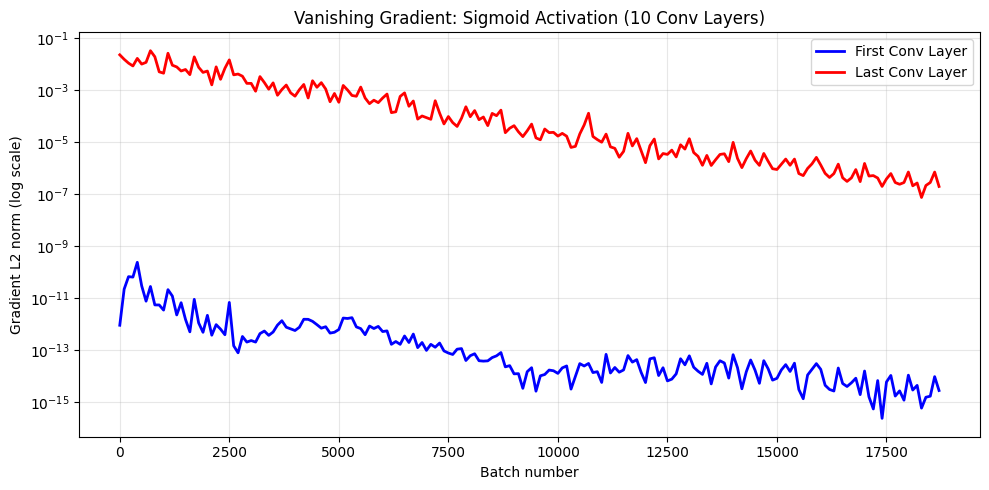

In [8]:
print("\n===== Experiment 1: Deep CNN with Sigmoid activation =====")
model_sigmoid = DeepCNN(num_layers=10, activation='sigmoid', weight_scale=0.02)  # Xavier-like init
grad_first_sig, grad_last_sig, losses_sig = train_and_record_gradients(
    model_sigmoid, train_loader, epochs=20, lr=0.001, log_batch_interval=100
)
plot_gradient_norms(grad_first_sig, grad_last_sig,
                    "Vanishing Gradient: Sigmoid Activation (10 Conv Layers)",
                    "gradient_norms_sigmoid.png")



===== Experiment 2: Deep CNN with ReLU activation =====
Batch     0 | Loss: 2.3026 | Grad norm (first conv): 2.519334e-08 | Grad norm (last conv): 6.617890e-03
Batch   100 | Loss: 2.3022 | Grad norm (first conv): 2.440347e-10 | Grad norm (last conv): 2.812113e-03
Batch   200 | Loss: 2.3035 | Grad norm (first conv): 1.294961e-03 | Grad norm (last conv): 9.977333e-03
Batch   300 | Loss: 2.0121 | Grad norm (first conv): 2.165891e+00 | Grad norm (last conv): 1.284369e+00
Batch   400 | Loss: 1.6176 | Grad norm (first conv): 1.243903e+00 | Grad norm (last conv): 1.651803e+00
Batch   500 | Loss: 1.6000 | Grad norm (first conv): 2.392532e+00 | Grad norm (last conv): 5.372156e+00
Batch   600 | Loss: 0.6558 | Grad norm (first conv): 6.083377e-01 | Grad norm (last conv): 1.296952e+00
Batch   700 | Loss: 0.5973 | Grad norm (first conv): 6.794862e-01 | Grad norm (last conv): 2.107060e+00
Batch   800 | Loss: 0.6310 | Grad norm (first conv): 7.141360e-01 | Grad norm (last conv): 6.006212e+00
Batch  

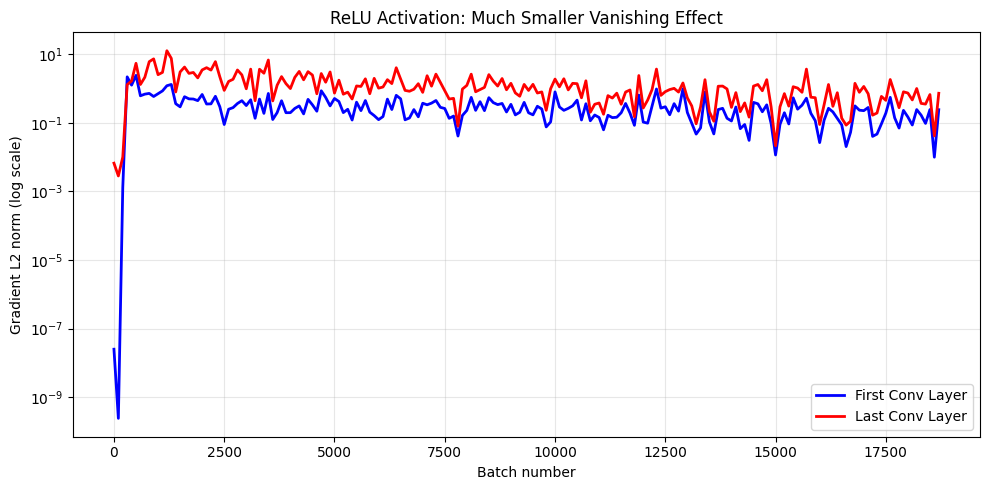

In [9]:
print("\n===== Experiment 2: Deep CNN with ReLU activation =====")
model_relu = DeepCNN(num_layers=10, activation='relu', weight_scale=0.02)
grad_first_relu, grad_last_relu, losses_relu = train_and_record_gradients(
    model_relu, train_loader, epochs=20, lr=0.001, log_batch_interval=100
)
plot_gradient_norms(grad_first_relu, grad_last_relu,
                    "ReLU Activation: Much Smaller Vanishing Effect",
                    "gradient_norms_relu.png")



===== Experiment 3: Sigmoid with large initial weights (scale=10) =====
Batch     0 | Loss: 44.5044 | Grad norm (first conv): 1.145631e+04 | Grad norm (last conv): 2.820922e+00
Batch   100 | Loss: 20.0899 | Grad norm (first conv): 1.134459e+04 | Grad norm (last conv): 1.395723e+00
Batch   200 | Loss: 10.6037 | Grad norm (first conv): 1.464446e+04 | Grad norm (last conv): 6.985611e-01
Batch   300 | Loss: 7.1565 | Grad norm (first conv): 9.952432e+03 | Grad norm (last conv): 6.115658e-01
Batch   400 | Loss: 5.7004 | Grad norm (first conv): 8.561771e+03 | Grad norm (last conv): 6.076584e-01
Batch   500 | Loss: 2.9306 | Grad norm (first conv): 8.494244e+03 | Grad norm (last conv): 6.011639e-01
Batch   600 | Loss: 2.5484 | Grad norm (first conv): 1.024997e+04 | Grad norm (last conv): 4.715951e-01
Batch   700 | Loss: 2.7935 | Grad norm (first conv): 1.020730e+04 | Grad norm (last conv): 2.648721e-01
Batch   800 | Loss: 2.6581 | Grad norm (first conv): 7.913033e+03 | Grad norm (last conv): 4

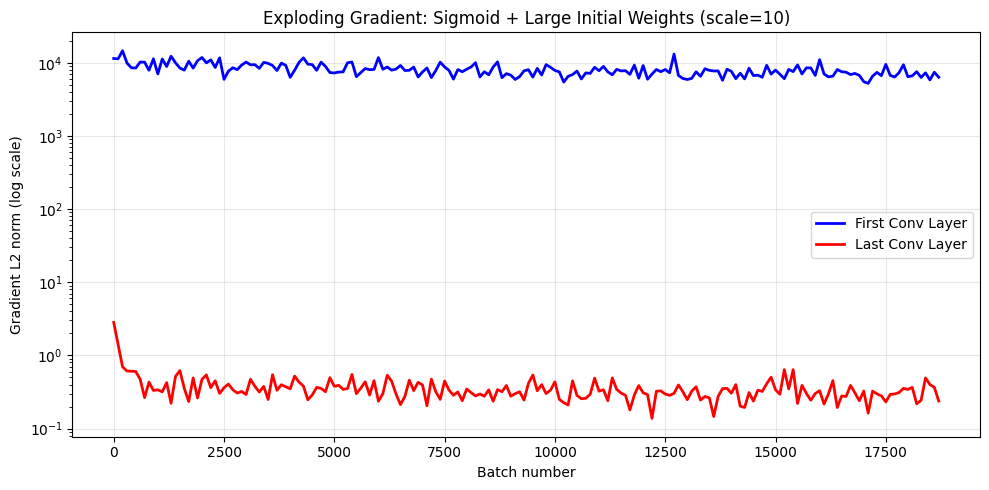

In [10]:
print("\n===== Experiment 3: Sigmoid with large initial weights (scale=10) =====")
model_large = DeepCNN(num_layers=10, activation='sigmoid', weight_scale=10.0)
grad_first_large, grad_last_large, losses_large = train_and_record_gradients(
    model_large, train_loader, epochs=20, lr=0.001, log_batch_interval=100
)
plot_gradient_norms(grad_first_large, grad_last_large,
                    "Exploding Gradient: Sigmoid + Large Initial Weights (scale=10)",
                    "gradient_norms_large_init.png")


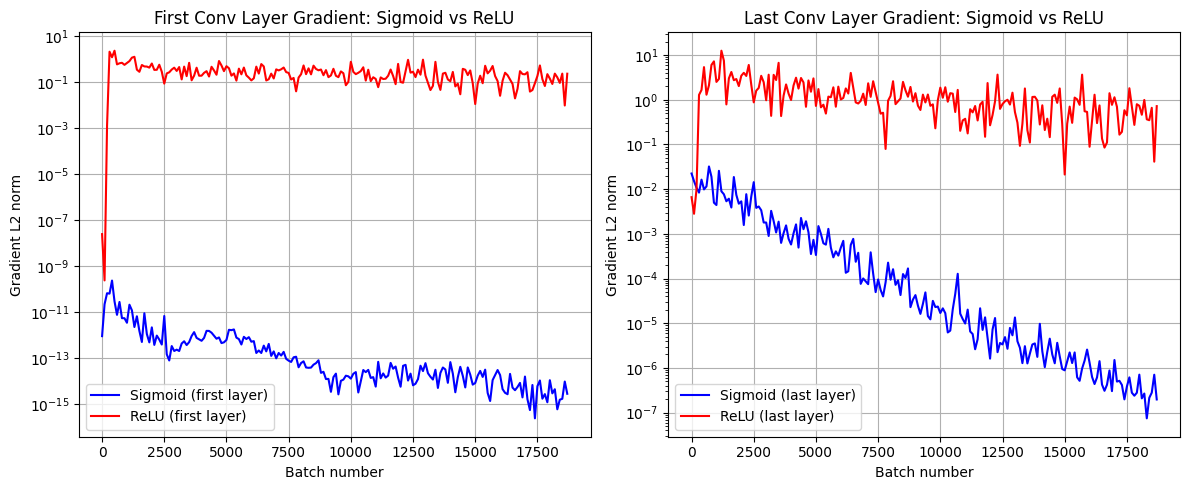

In [11]:
plt.figure(figsize=(12, 5))
# First layer comparison
batches_sig, norms_first_sig = zip(*grad_first_sig)
batches_relu, norms_first_relu = zip(*grad_first_relu)
plt.subplot(1, 2, 1)
plt.plot(batches_sig, norms_first_sig, 'b-', label='Sigmoid (first layer)')
plt.plot(batches_relu, norms_first_relu, 'r-', label='ReLU (first layer)')
plt.yscale('log')
plt.xlabel('Batch number')
plt.ylabel('Gradient L2 norm')
plt.title('First Conv Layer Gradient: Sigmoid vs ReLU')
plt.legend()
plt.grid(True)

# Last layer comparison
batches_sig, norms_last_sig = zip(*grad_last_sig)
batches_relu, norms_last_relu = zip(*grad_last_relu)
plt.subplot(1, 2, 2)
plt.plot(batches_sig, norms_last_sig, 'b-', label='Sigmoid (last layer)')
plt.plot(batches_relu, norms_last_relu, 'r-', label='ReLU (last layer)')
plt.yscale('log')
plt.xlabel('Batch number')
plt.ylabel('Gradient L2 norm')
plt.title('Last Conv Layer Gradient: Sigmoid vs ReLU')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('sigmoid_vs_relu_gradients.png', dpi=150)
plt.show()


In [12]:
print("\n===== Summary of Observations =====")
print("1. Sigmoid activation: Gradients of first conv layer are orders of magnitude smaller than those of the last conv layer (vanishing gradient).")
print("2. ReLU activation: Gradients remain relatively large even in early layers, mitigating vanishing gradient.")
print("3. Large initial weights (scale=10) cause extremely large gradient norms (often > 1e6), leading to numerical instability (exploding gradient).")

# Save raw data to CSV for further analysis
import pandas as pd
def save_grad_data(grad_first, grad_last, name):
    df = pd.DataFrame({
        'batch': [b for b,_ in grad_first],
        'grad_norm_first': [n for _,n in grad_first],
        'grad_norm_last': [n for _,n in grad_last]
    })
    df.to_csv(f'gradient_data_{name}.csv', index=False)

save_grad_data(grad_first_sig, grad_last_sig, 'sigmoid')
save_grad_data(grad_first_relu, grad_last_relu, 'relu')
save_grad_data(grad_first_large, grad_last_large, 'large_init')
print("\nGradient data saved to CSV files.")


===== Summary of Observations =====
1. Sigmoid activation: Gradients of first conv layer are orders of magnitude smaller than those of the last conv layer (vanishing gradient).
2. ReLU activation: Gradients remain relatively large even in early layers, mitigating vanishing gradient.
3. Large initial weights (scale=10) cause extremely large gradient norms (often > 1e6), leading to numerical instability (exploding gradient).

Gradient data saved to CSV files.
